# Prédire le Nutri-Score — TP 14 et TP 15

Classification du grade A→E à partir des caractéristiques produit, puis comparaison des
méthodes d'ensemble à conditions égales.

Règles du protocole, tenues par `nutriscope.classification` :

- la colonne `split` figée au TP 13 n'est jamais recalculée ;
- toute la préparation vit dans le pipeline (`make_model`), ajustée sur le seul train de chaque pli ;
- les plis (`make_cv`) et les métriques (`SCORING`) sont les mêmes pour tous les modèles ;
- la validation croisée se fait **à l'intérieur du train** ; le test n'est regardé **qu'une fois**, à la dernière section ;
- `code`, `product_name`, `brands`, `split` et `nutriscore_score` ne sont jamais des features.

Données : Open Food Facts — **© Open Food Facts contributors — ODbL**.

In [5]:
import time
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import cross_val_predict
from sklearn.tree import DecisionTreeClassifier

from nutriscope.classification import (
    GRADES,
    SPLIT,
    TARGET,
    FlatClassifier,
    cross_validate_models,
    dataset_path,
    decode_grades,
    load_dataset,
    make_cv,
    make_model,
    normalized_confusion,
    preparation,
    split_frame,
    test_scores,
)
from nutriscope.options import RANDOM_SEED as SEED

pd.set_option("display.precision", 3)

In [6]:
df = load_dataset()
print(dataset_path())
df.info()

C:\Users\shink\Desktop\Nutriscope\app\data-nutriscope\nutriscope_ml_sample.parquet
<class 'pandas.DataFrame'>
RangeIndex: 30041 entries, 0 to 30040
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   code                            30041 non-null  str    
 1   product_name                    29655 non-null  str    
 2   brands                          23770 non-null  str    
 3   pnns_groups_1                   30041 non-null  str    
 4   pnns_groups_2                   30041 non-null  str    
 5   nova_group                      16938 non-null  Int64  
 6   additives_n                     17653 non-null  Int64  
 7   energy-kcal_100g                30041 non-null  float64
 8   fat_100g                        30041 non-null  float64
 9   saturated-fat_100g              30041 non-null  float64
 10  carbohydrates_100g              30041 non-null  float64
 11  sugars_100g          

In [7]:
# Split figé du TP 13 : jamais recalculé. La cible est codée 0-4 (a-e) pour tous les modèles.
X_train, X_test, y_train, y_test = split_frame(df)
cv = make_cv()

# Point de contrôle 6 : deux appels à cv.split rendent exactement les mêmes plis
assert all(
    np.array_equal(a, b)
    for (_, a), (_, b) in zip(cv.split(X_train, y_train), cv.split(X_train, y_train))
)
X_train.shape, X_test.shape

((24076, 13), (5965, 13))

## Baselines

Validation croisée 5 plis stratifiée, **sur le train uniquement** : F1 macro avec son
écart-type, accuracy, accuracy équilibrée.

In [8]:
baselines = {
    "Dummy most_frequent": make_model(DummyClassifier(strategy="most_frequent")),
    "Dummy stratified": make_model(DummyClassifier(strategy="stratified", random_state=SEED)),
    "DecisionTree depth 3": make_model(DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    "DecisionTree depth 8": make_model(DecisionTreeClassifier(max_depth=8, random_state=SEED)),
}
baseline_scores = cross_validate_models(baselines, X_train, y_train, cv=cv)
display(baseline_scores)

majority = baseline_scores.loc["Dummy most_frequent"]
print(f"Classe majoritaire : accuracy / F1 macro = "
      f"{majority['accuracy_mean'] / majority['f1_macro_mean']:.1f}")

,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,fit_time_s,predict_time_s
model,,,,,,,,
Dummy most_frequent,0.089,2.584e-05,0.286,1.068e-04,0.200,0.000,0.153,0.032
Dummy stratified,0.200,6.873e-03,0.226,7.752e-03,0.200,0.007,0.163,0.026
DecisionTree depth 3,0.361,9.145e-04,0.521,1.607e-03,0.417,0.002,0.204,0.025
DecisionTree depth 8,0.740,6.935e-03,0.770,7.242e-03,0.737,0.007,0.309,0.026


Classe majoritaire : accuracy / F1 macro = 3.2


## Modèles du TP 14 : régression logistique multinomiale et forêt aléatoire

Même préparation pour tous (`preparation()`) : features dérivées dans le pipeline,
imputation médiane avec indicateur de manquant pour les colonnes optionnelles,
standardisation, one-hot des rayons avec regroupement des rayons rares.

In [9]:
# Point de contrôle 4 : une soixantaine de colonnes en sortie du préparateur
n_columns = preparation().fit(X_train).transform(X_train).shape[1]
print(f"{X_train.shape[1]} colonnes brutes -> {n_columns} colonnes préparées")

models = {
    "LogisticRegression": make_model(LogisticRegression(max_iter=3000, class_weight="balanced")),
    "RandomForest": make_model(RandomForestClassifier(random_state=SEED, n_jobs=-1)),
}
tp14_scores = cross_validate_models(models, X_train, y_train, cv=cv)
display(tp14_scores)

13 colonnes brutes -> 67 colonnes préparées


,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,fit_time_s,predict_time_s
model,,,,,,,,
LogisticRegression,0.781,0.007,0.804,0.005,0.786,0.006,1.623,0.026
RandomForest,0.856,0.007,0.875,0.005,0.851,0.007,1.715,0.110


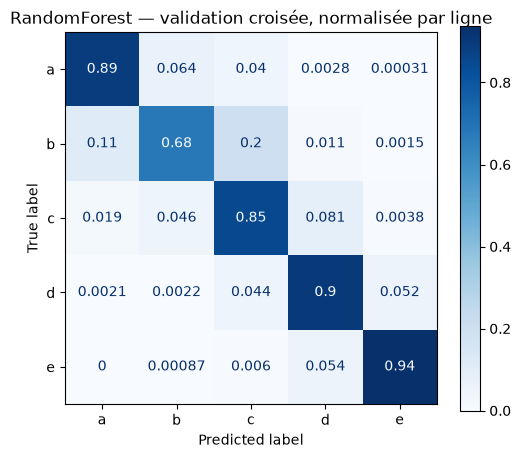

In [10]:
# Matrice de confusion du meilleur modèle, sur les prédictions hors pli du train (le test reste fermé).
# Normalisée par ligne : chaque case est un rappel (point de contrôle 5).
y_oof = cross_val_predict(models["RandomForest"], X_train, y_train, cv=cv, n_jobs=-1)
matrix = normalized_confusion(y_train, y_oof)
assert np.allclose(matrix.sum(axis=1), 1.0)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=matrix.to_numpy(), display_labels=GRADES).plot(ax=ax, cmap="Blues")
ax.set_title("RandomForest — validation croisée, normalisée par ligne")
plt.show()

## Déséquilibre des classes

In [11]:
distribution = pd.Series(decode_grades(y_train)).value_counts(normalize=True).sort_index()
ratio = distribution.max() / distribution.min()
print(distribution.round(2))
print(f"Ratio classe majoritaire / classe minoritaire : {ratio:.1f}")

a    0.13
b    0.11
c    0.21
d    0.26
e    0.29
Name: proportion, dtype: float64
Ratio classe majoritaire / classe minoritaire : 2.6


In [12]:
# SMOTE DANS le pipeline imblearn : il ne rééchantillonne que le train de chaque pli.
# imblearn refuse un Pipeline scikit-learn comme étape intermédiaire : on aplatit la préparation.
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

imbalance = {
    "RandomForest": models["RandomForest"],
    "RandomForest balanced": make_model(
        RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)
    ),
    "RandomForest + SMOTE": ImbPipeline([
        *preparation().steps,
        ("smote", SMOTE(random_state=SEED)),
        ("model", RandomForestClassifier(random_state=SEED, n_jobs=-1)),
    ]),
}
imbalance_scores = cross_validate_models(imbalance, X_train, y_train, cv=cv)
display(imbalance_scores)

,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,fit_time_s,predict_time_s
model,,,,,,,,
RandomForest,0.856,0.007,0.875,0.005,0.851,0.007,1.356,0.338
RandomForest balanced,0.856,0.008,0.873,0.007,0.856,0.008,1.403,0.423
RandomForest + SMOTE,0.857,0.004,0.875,0.004,0.858,0.004,2.668,0.122


## Boosting (TP 15)

Quatre implémentations, mêmes conditions : même préparation, mêmes plis, mêmes métriques,
même `split`. CatBoost est enveloppé dans `FlatClassifier` (ses prédictions multiclasses
ont la forme (n, 1)) et n'écrit rien sur le disque.

In [13]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

boosters = {
    "XGBoost": make_model(XGBClassifier(random_state=SEED)),
    "LightGBM": make_model(LGBMClassifier(random_state=SEED, verbosity=-1)),
    "CatBoost": make_model(FlatClassifier(CatBoostClassifier(
        random_seed=SEED, verbose=0, allow_writing_files=False, train_dir=tempfile.mkdtemp(),
    ))),
    "HistGradientBoosting": make_model(HistGradientBoostingClassifier(random_state=SEED)),
}
booster_scores = cross_validate_models(boosters, X_train, y_train, cv=cv)
display(booster_scores)

,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,fit_time_s,predict_time_s
model,,,,,,,,
XGBoost,0.894,0.007,0.911,0.005,0.893,0.007,3.699,0.074
LightGBM,0.888,0.010,0.906,0.008,0.887,0.009,2.766,0.067
CatBoost,0.889,0.005,0.907,0.004,0.887,0.005,31.321,0.048
HistGradientBoosting,0.890,0.005,0.908,0.005,0.889,0.005,6.992,0.178


## Optimisation de XGBoost

**Budget, annoncé avant de lancer** : 30 essais Optuna (échantillonneur TPE, graine 42),
3 plis stratifiés pendant la recherche puis les 5 plis communs pour la mesure finale,
`MedianPruner` nourri par le score cumulé après chaque pli. Durée attendue : estimée par la
cellule suivante à partir du temps d'ajustement mesuré ci-dessus.

**Espace** : profondeur 2-10 et 50-800 arbres (au-delà, le gain est marginal sur 24 000
produits et le coût double) ; taux d'apprentissage 0,01-0,5 en échelle logarithmique ;
sous-échantillonnage 0,6-1 contre le surapprentissage.

In [14]:
N_TRIALS = 30
N_FOLDS_SEARCH = 3

fit_time = booster_scores.loc["XGBoost", "fit_time_s"]
print(f"Estimation : {N_TRIALS} essais × {N_FOLDS_SEARCH} plis × {fit_time:.1f} s "
      f"≈ {N_TRIALS * N_FOLDS_SEARCH * fit_time / 60:.0f} min (hors élagage)")

Estimation : 30 essais × 3 plis × 3.7 s ≈ 6 min (hors élagage)


In [15]:
import optuna
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)
search_folds = list(make_cv(n_splits=N_FOLDS_SEARCH).split(X_train, y_train))


def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "n_estimators": trial.suggest_int("n_estimators", 50, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.5, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
    }
    model = make_model(XGBClassifier(random_state=SEED, **params))
    scores = []
    for step, (fit_index, valid_index) in enumerate(search_folds):
        model.fit(X_train.iloc[fit_index], y_train[fit_index])
        predictions = model.predict(X_train.iloc[valid_index])
        scores.append(f1_score(y_train[valid_index], predictions, average="macro"))
        trial.report(np.mean(scores), step)       # alimente le MedianPruner
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(scores)


study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEED),
    pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=1),
)
start = time.perf_counter()
study.optimize(objective, n_trials=N_TRIALS)
search_minutes = (time.perf_counter() - start) / 60

pruned = sum(trial.state == optuna.trial.TrialState.PRUNED for trial in study.trials)
print(f"Temps réel : {search_minutes:.1f} min, {pruned} essais élagués sur {N_TRIALS}")
print(f"Meilleur F1 macro (3 plis) : {study.best_value:.3f}")
print(f"Meilleurs paramètres : {study.best_params}")

c:\Users\shink\Desktop\Nutriscope\app\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Temps réel : 11.2 min, 4 essais élagués sur 30
Meilleur F1 macro (3 plis) : 0.895
Meilleurs paramètres : {'max_depth': 10, 'n_estimators': 568, 'learning_rate': 0.035724999767510104, 'subsample': 0.9079137637914403}


In [16]:
# Mesure finale du modèle réglé sur les 5 plis communs, puis gain confronté à l'écart-type
tuned = {"XGBoost tuned": make_model(XGBClassifier(random_state=SEED, **study.best_params))}
tuned_scores = cross_validate_models(tuned, X_train, y_train, cv=cv)

gain = tuned_scores.loc["XGBoost tuned", "f1_macro_mean"] - booster_scores.loc["XGBoost", "f1_macro_mean"]
noise = 2 * booster_scores.loc["XGBoost", "f1_macro_std"]
print(f"Gain du réglage : {gain:+.4f} — deux écarts-types des plis : {noise:.4f} -> "
      f"{'significatif' if gain > noise else 'non significatif'}")

Gain du réglage : +0.0044 — deux écarts-types des plis : 0.0136 -> non significatif


## Tableau unique (validation croisée sur le train)

In [17]:
candidates = {**models, **boosters, **tuned}
comparison = pd.concat([tp14_scores, booster_scores, tuned_scores])
display(comparison.sort_values("f1_macro_mean", ascending=False))

,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,fit_time_s,predict_time_s
model,,,,,,,,
XGBoost tuned,0.898,0.007,0.914,0.005,0.897,0.007,42.237,0.769
XGBoost,0.894,0.007,0.911,0.005,0.893,0.007,3.699,0.074
HistGradientBoosting,0.890,0.005,0.908,0.005,0.889,0.005,6.992,0.178
CatBoost,0.889,0.005,0.907,0.004,0.887,0.005,31.321,0.048
LightGBM,0.888,0.010,0.906,0.008,0.887,0.009,2.766,0.067
RandomForest,0.856,0.007,0.875,0.005,0.851,0.007,1.715,0.110
LogisticRegression,0.781,0.007,0.804,0.005,0.786,0.006,1.623,0.026


## Évaluation finale sur le test — une seule fois

Toutes les décisions sont prises au-dessus, sur la validation croisée. Chaque modèle est
ajusté sur **tout** le train, puis prédit le test une seule fois ; les chiffres sont
écrits avant d'être commentés.

In [18]:
test_rows = {}
fitted = {}
for name, model in candidates.items():
    fitted[name] = model.fit(X_train, y_train)
    test_rows[name] = test_scores(fitted[name], X_test, y_test)

final = comparison.join(pd.DataFrame(test_rows).T)
final["cv_test_gap"] = final["f1_macro_mean"] - final["f1_macro_test"]
display(final[["f1_macro_mean", "f1_macro_std", "f1_macro_test", "accuracy_test", "cv_test_gap",
               "fit_time_s", "predict_time_s", "latency_ms_per_product"]]
        .sort_values("f1_macro_mean", ascending=False))

,f1_macro_mean,f1_macro_std,f1_macro_test,accuracy_test,cv_test_gap,fit_time_s,predict_time_s,latency_ms_per_product
model,,,,,,,,
XGBoost tuned,0.898,0.007,0.899,0.914,-5.936e-04,42.237,0.769,0.023
XGBoost,0.894,0.007,0.895,0.911,-6.794e-04,3.699,0.074,0.007
HistGradientBoosting,0.890,0.005,0.888,0.905,1.616e-03,6.992,0.178,0.013
CatBoost,0.889,0.005,0.885,0.903,3.961e-03,31.321,0.048,0.005
LightGBM,0.888,0.010,0.886,0.903,1.918e-03,2.766,0.067,0.012
RandomForest,0.856,0.007,0.856,0.875,-7.255e-04,1.715,0.110,0.012
LogisticRegression,0.781,0.007,0.782,0.806,-1.705e-03,1.623,0.026,0.004


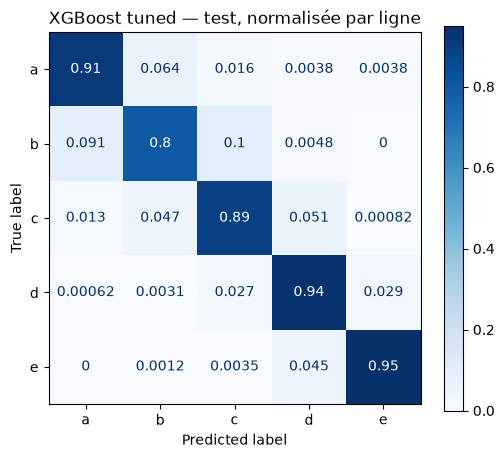

In [19]:
# Matrice de confusion sur le test du meilleur modèle en validation croisée
best = comparison["f1_macro_mean"].idxmax()
y_pred = np.asarray(fitted[best].predict(X_test)).ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=normalized_confusion(y_test, y_pred).to_numpy(),
                       display_labels=GRADES).plot(ax=ax, cmap="Blues")
ax.set_title(f"{best} — test, normalisée par ligne")
plt.show()

> Confusions (a>b) et (c>b)

**Lecture.** Sur la matrice du modèle réglé, le grade b concentre les confusions : il
attire des a et des c, et en perd vers les deux. L'analyse détaillée porte sur le
modèle retenu, plus bas : section « Le grade b, pris en étau entre a et c ».

In [20]:
# Prédictions du test remontées aux produits, pour l'analyse d'erreurs
predictions = df.loc[X_test.index, ["code", "product_name", "brands", *X_test.columns, TARGET]].copy()
predictions[f"{TARGET}_pred"] = decode_grades(y_pred)
errors = predictions[predictions[TARGET] != predictions[f"{TARGET}_pred"]]
print(f"{len(errors):,} erreurs sur {len(predictions):,} produits du test")
errors.head()

512 erreurs sur 5,965 produits du test


,code,product_name,brands,pnns_groups_1,pnns_groups_2,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,salt_100g,fiber_100g,fruits-vegetables-legumes_100g,nova_group,additives_n,nutriscore_grade,nutriscore_grade_pred
19,0001002239823,Coco Light Syrup,Maya Gold,Sugary snacks,Sweets,312.000,0.800,0.000,78.000,78.000,0.0,0.057,0.000,0.00,2,0,e,d
22,0001002842941,Ice cream sticks Vanilla,Leone,Milk and dairy products,Ice cream,124.000,5.200,4.700,10.000,1.100,12.0,0.290,NaN,0.00,4,5,b,c
60,0010041001140,Lait de coco,Jaja,Beverages,Plant-based milk substitutes,297.000,28.000,14.000,0.350,0.000,3.5,0.280,3.500,75.00,1,0,d,e
109,00168069,NaN,Marks & Spencer,Cereals and potatoes,Bread,207.273,1.273,0.182,40.182,3.091,6.0,1.377,6.182,23.75,4,2,c,b
110,0017600023353,"Louisiana Gold, Green Sauce With Tabasco Peppers",Bruce Foods Inc.,Fat and sauces,Dressings and sauces,0.000,0.000,0.000,0.000,0.000,0.0,13.000,NaN,62.50,3,0,d,e


## Critères de décision mesurés (ADR)

Les six critères de l'ADR, mesurés et non estimés : performance (F1 macro CV et test),
latence (temps de prédiction du test divisé par le nombre de produits, colonne
`latency_ms_per_product`), taille (`joblib.dump` puis taille du fichier), coût de
réentraînement (`fit_time_s`, temps moyen d'ajustement d'un pli). Les modèles sont
sérialisés dans un dossier temporaire : rien n'est écrit dans le dépôt.

In [21]:
import joblib
from pathlib import Path

model_dir = Path(tempfile.mkdtemp())
sizes = {}
for name, model in fitted.items():
    model_path = model_dir / f"{name.replace(' ', '_')}.joblib"
    joblib.dump(model, model_path)
    sizes[name] = model_path.stat().st_size / 1024

criteria = final.assign(size_ko=pd.Series(sizes))[
    ["f1_macro_mean", "f1_macro_std", "f1_macro_test", "accuracy_test",
     "fit_time_s", "latency_ms_per_product", "size_ko"]
].sort_values("f1_macro_mean", ascending=False)
display(criteria)

leader = criteria["f1_macro_mean"].idxmax()
threshold = criteria.loc[leader, "f1_macro_mean"] - criteria.loc[leader, "f1_macro_std"]
tied = criteria.index[criteria["f1_macro_mean"] >= threshold].tolist()
print(f"À moins d'un écart-type ({criteria.loc[leader, 'f1_macro_std']:.4f}) de {leader} : {tied}")

,f1_macro_mean,f1_macro_std,f1_macro_test,accuracy_test,fit_time_s,latency_ms_per_product,size_ko
model,,,,,,,
XGBoost tuned,0.898,0.007,0.899,0.914,42.237,0.023,27479.687
XGBoost,0.894,0.007,0.895,0.911,3.699,0.007,1721.312
HistGradientBoosting,0.890,0.005,0.888,0.905,6.992,0.013,1799.197
CatBoost,0.889,0.005,0.885,0.903,31.321,0.005,3113.662
LightGBM,0.888,0.010,0.886,0.903,2.766,0.012,1704.288
RandomForest,0.856,0.007,0.856,0.875,1.715,0.012,78558.144
LogisticRegression,0.781,0.007,0.782,0.806,1.623,0.004,11.166


À moins d'un écart-type (0.0066) de XGBoost tuned : ['XGBoost tuned', 'XGBoost']


**Lecture.** XGBoost par défaut pèse 1,7 Mo pour 7 µs de prédiction par produit. La
version réglée pèse 27,5 Mo, s'ajuste onze fois plus lentement (42,2 s par pli contre
3,7 s), pour un gain de F1 macro non significatif (+0,0044, sous deux écarts-types). La
forêt du TP 14 pèse 78,6 Mo. Décision et critères : `docs/decisions/ADR-001-modele-nutriscore.md`.

**Modèle retenu** : XGBoost avec ses paramètres par défaut — justification dans
`docs/decisions/ADR-001-modele-nutriscore.md`. Le réglage Optuna n'apporte pas de gain
significatif (inférieur à deux écarts-types), pour un ajustement environ dix fois plus long.
Les analyses qui suivent portent sur ce modèle.

In [22]:
RETAINED = "XGBoost"
retained = fitted[RETAINED]

proba = retained.predict_proba(X_test)
y_hat = proba.argmax(axis=1)
order = np.sort(proba, axis=1)

# nutriscore_score n'est PAS une feature : il sert uniquement à lire les erreurs
analysis = df.loc[X_test.index, ["code", "product_name", "brands", *X_test.columns,
                                 "nutriscore_score", TARGET]].copy()
analysis["pred"] = decode_grades(y_hat)
analysis["confidence"] = order[:, -1]
analysis["margin"] = order[:, -1] - order[:, -2]
analysis["gap"] = np.abs(y_hat - y_test)
wrong = analysis[analysis["gap"] > 0]

print(f"{RETAINED} — F1 macro test {f1_score(y_test, y_hat, average='macro'):.3f}, "
      f"{len(wrong):,} erreurs sur {len(analysis):,} produits ({len(wrong) / len(analysis):.1%})")

XGBoost — F1 macro test 0.895, 532 erreurs sur 5,965 produits (8.9%)


## Ce que le modèle rate (TP 15, étape 4)

### Matrice de confusion normalisée par ligne et rappel par grade

predicted,a,b,c,d,e
true,,,,,
a,0.913,0.059,0.021,0.003,0.004
b,0.107,0.785,0.103,0.005,0.000
c,0.012,0.049,0.882,0.056,0.001
d,0.001,0.003,0.028,0.939,0.029
e,0.000,0.001,0.003,0.047,0.949


,recall,main_confusion,main_confusion_share
a,0.913,b,0.059
b,0.785,a,0.107
c,0.882,d,0.056
d,0.939,e,0.029
e,0.949,d,0.047


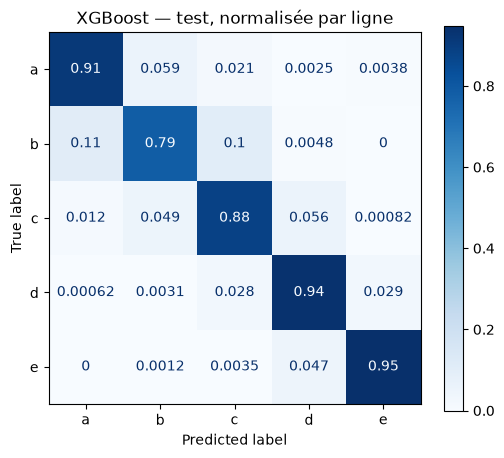

In [23]:
matrix = normalized_confusion(y_test, y_hat)
display(matrix.round(3))

recall = pd.Series(np.diag(matrix), index=GRADES, name="recall")
leaks_to = matrix.where(~np.eye(len(GRADES), dtype=bool)).idxmax(axis=1).rename("main_confusion")
leak_share = matrix.where(~np.eye(len(GRADES), dtype=bool)).max(axis=1).rename("main_confusion_share")
display(pd.concat([recall, leaks_to, leak_share], axis=1).round(3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=matrix.to_numpy(), display_labels=GRADES).plot(ax=ax, cmap="Blues")
ax.set_title(f"{RETAINED} — test, normalisée par ligne")
plt.show()

**Lecture.** b est la seule classe sous 0,88 de rappel (0,785). Elle fuit des deux côtés,
presque à parts égales : 10,7 % vers a et 10,3 % vers c. Les extrêmes a et e sont bien
reconnus (0,913 et 0,949), et les confusions entre grades non voisins restent rares.

### Les cinq couples (réel, prédit) les plus fréquents parmi les erreurs

In [24]:
pairs = wrong.groupby([TARGET, "pred"]).size().rename("n").sort_values(ascending=False)
top_pairs = pairs.head(5).to_frame()
top_pairs["share_of_errors"] = top_pairs["n"] / len(wrong)
display(top_pairs.round(3))

n  share_of_errors
nutriscore_grade pred                     
e                d     80            0.150
c                d     68            0.128
b                a     67            0.126
                 c     65            0.122
c                b     60            0.113

**Lecture.** Les cinq couples les plus fréquents opposent tous deux grades voisins, et
trois d'entre eux impliquent b (b→a, b→c, c→b). La première confusion, e→d, est aussi
la plus bénigne pour l'utilisateur : le produit reste classé parmi les moins bons.

### Gravité des erreurs : nombre de crans d'écart

In [25]:
severity = (wrong["gap"].clip(upper=3)
            .map({1: "1 cran", 2: "2 crans", 3: "3 crans ou plus"})
            .value_counts().reindex(["1 cran", "2 crans", "3 crans ou plus"], fill_value=0)
            .rename("n").to_frame())
severity["share_of_errors"] = severity["n"] / len(wrong)
severity["share_of_test"] = severity["n"] / len(analysis)
display(severity.round(4))
print(f"Prédictions exactes ou à un cran près : {(analysis['gap'] <= 1).mean():.1%} du test")

,n,share_of_errors,share_of_test
gap,,,
1 cran,478,0.898,0.080
2 crans,46,0.086,0.008
3 crans ou plus,8,0.015,0.001


Prédictions exactes ou à un cran près : 99.1% du test


**Lecture.** 89,8 % des erreurs sont à un seul cran, et 99,1 % du test reçoit le bon
grade ou un grade voisin. Les 54 erreurs de deux crans ou plus (0,9 % du test) sont
celles qui faussent vraiment la décision d'achat.

### Performance par rayon (`pnns_groups_1`), du pire au meilleur

`n_train` : effectif du rayon dans le train, ce que le modèle a vu pour apprendre.

In [26]:
from sklearn.metrics import accuracy_score

train_counts = X_train["pnns_groups_1"].value_counts()
rows = []
for group, part in analysis.groupby("pnns_groups_1"):
    rows.append({
        "pnns_groups_1": group,
        "n_train": int(train_counts.get(group, 0)),
        "n_test": len(part),
        "f1_macro": f1_score(part[TARGET], part["pred"], average="macro", zero_division=0),
        "accuracy": accuracy_score(part[TARGET], part["pred"]),
        "errors_2_plus": int((part["gap"] >= 2).sum()),
    })
by_group = pd.DataFrame(rows).set_index("pnns_groups_1").sort_values("f1_macro")
display(by_group.round(3))

,n_train,n_test,f1_macro,accuracy,errors_2_plus
pnns_groups_1,,,,,
Alcoholic beverages,33,10,0.308,0.600,3
Fruits and vegetables,1660,403,0.829,0.864,10
Sugary snacks,5138,1349,0.830,0.950,6
Cereals and potatoes,2661,603,0.844,0.854,8
Composite foods,2082,494,0.856,0.887,4
Fat and sauces,1770,422,0.886,0.903,3
Beverages,1762,471,0.891,0.890,4
Fish Meat Eggs,4384,1110,0.893,0.924,5
Milk and dairy products,3053,715,0.903,0.926,7


**Lecture.** Les boissons alcoolisées ne sont pas couvertes : 33 produits d'entraînement,
F1 macro de 0,31, et un barème qui ne s'y applique pas. Les fruits et légumes cumulent le
plus d'erreurs graves (10). Pour les produits sucrés, le F1 macro (0,830) est trompeur :
l'accuracy est de 0,950, mais les classes rares du rayon tirent la moyenne vers le bas.

### Cinq produits réels sur lesquels le modèle hésite entre deux classes voisines

Produits du test dont les deux grades les plus probables sont b/c ou d/e, triés par marge
croissante entre ces deux probabilités (hésitation maximale). Le score officiel
`nutriscore_score` est affiché pour la lecture seulement. Seuils du barème 2023 (aliments
généraux) : A ≤ 0, B 1-2, C 3-10, D 11-18, E ≥ 19 ; les boissons, les matières grasses et
les fromages ont des grilles spécifiques.

In [27]:
top_two = np.argsort(proba, axis=1)[:, -2:]
pair_bc = np.isin(top_two, [1, 2]).all(axis=1)
pair_de = np.isin(top_two, [3, 4]).all(axis=1)

columns = ["code", "product_name", "brands", "pnns_groups_1", "pnns_groups_2",
           "energy-kcal_100g", "sugars_100g", "saturated-fat_100g", "salt_100g",
           "fiber_100g", "proteins_100g", "fruits-vegetables-legumes_100g",
           "nutriscore_score", TARGET, "pred", "confidence", "margin"]
hesitant_bc = analysis.loc[pair_bc].sort_values("margin").head(5)[columns]
hesitant_de = analysis.loc[pair_de].sort_values("margin").head(5)[columns]

with pd.option_context("display.max_columns", None, "display.width", 250):
    print("Hésitations b/c")
    display(hesitant_bc)
    print("Hésitations d/e")
    display(hesitant_de)

Hésitations b/c


,code,product_name,brands,pnns_groups_1,pnns_groups_2,energy-kcal_100g,sugars_100g,saturated-fat_100g,salt_100g,fiber_100g,proteins_100g,fruits-vegetables-legumes_100g,nutriscore_score,nutriscore_grade,pred,confidence,margin
3651,2250718032345,Dos de cabillaud beurre et persil décongelé,Appeti Marine,Fish Meat Eggs,Fish and seafood,202.0,0.60,3.50,0.80,NaN,13.0,NaN,3,c,b,0.475,3.074e-04
19667,3760039500090,Anchoiade,NaN,Salty snacks,Salty and fatty products,436.0,0.14,4.65,0.01,NaN,14.0,NaN,4,c,c,0.414,3.171e-03
25825,7610900066995,ENERGY MILK NEW 26g HIGH PROTEIN Vanilla,Emmi,Beverages,Sweetened beverages,64.0,4.50,0.90,0.33,NaN,8.0,2.250,2,b,b,0.445,4.598e-03
11899,3287370002682,Brandade de morue parmentiere,Fastcity,Composite foods,One-dish meals,133.0,1.04,0.97,0.67,NaN,5.1,0.831,2,b,c,0.501,7.411e-03
5590,3021690026405,Boulettes cuisinées a l'orientale,Casa d'Oro,Composite foods,One-dish meals,85.0,1.90,0.10,0.83,NaN,6.3,44.264,2,b,b,0.441,1.071e-02


Hésitations d/e


,code,product_name,brands,pnns_groups_1,pnns_groups_2,energy-kcal_100g,sugars_100g,saturated-fat_100g,salt_100g,fiber_100g,proteins_100g,fruits-vegetables-legumes_100g,nutriscore_score,nutriscore_grade,pred,confidence,margin
5109,2852160024932,Filet de haddock sans colorant,NaN,Fish Meat Eggs,Fish and seafood,316.0,0.0,0.0,3.200,NaN,18.0,NaN,15,d,e,0.482,0.006
2688,2011570599991,Chocolientjes,Hema,Sugary snacks,Biscuits and cakes,463.0,8.8,8.8,0.780,1.6,6.6,NaN,17,d,e,0.500,0.008
19980,3760083873751,Nougat,NaN,Sugary snacks,Sweets,459.0,44.2,1.7,0.022,NaN,10.8,NaN,19,e,e,0.506,0.016
5513,3018170401531,Merguez boeuf,Les Occitanes,Fish Meat Eggs,Processed meat,196.0,0.5,8.5,1.900,NaN,16.0,NaN,19,e,e,0.508,0.017
6625,3113010133037,Foie Gras de Canard Entier au Cognac,Larnaudie,Salty snacks,Salty and fatty products,571.0,1.0,26.7,0.540,NaN,7.2,0.0,19,e,e,0.510,0.026


**Lecture : diagnostic de cinq produits** (point de contrôle 5). Trois diagnostics
possibles : donnée fausse, règle métier absente, ou limite du modèle.

| Produit | Score → grade | Prédit | Diagnostic |
| --- | --- | --- | --- |
| Dos de cabillaud (2250718032345) | 3 → C | b | **Limite du modèle** : premier point de C, sur la frontière B/C |
| Nougat (3760083873751) | 19 → E | e | **Limite du modèle** : premier point de E, sur la frontière D/E |
| Merguez bœuf (3018170401531) | 19 → E | e | **Règle métier absente** : le barème plafonne les points protéines de la viande rouge, et aucune feature ne la signale |
| Energy Milk (7610900066995) | 2 → B | b | **Règle métier absente** : les boissons lactées suivent depuis 2023 la grille des boissons, que le modèle ne connaît qu'à travers le rayon |
| Filet de haddock (2852160024932) | 15 → D | e | **Donnée fausse probable** : 316 kcal pour 18 g de protéines et 0 g de sucres, incohérent pour un poisson maigre ; le score est au milieu de D, donc pas sur une frontière |

Un seul diagnostic sur cinq relève de l'apprentissage. Actions et règles d'usage :
`docs/ml/limites_nutriscore.md`.

### Le grade b, pris en étau entre a et c

La matrice montre que b est la classe la moins bien reconnue, et qu'elle fuit des deux
côtés : vers a et vers c. Inversement, des a et des c sont prédits b. Sur la grille des
aliments généraux (2023), B ne couvre que **deux points** de score (1 et 2), contre huit
pour C (3 à 10) et D (11 à 18) : tout produit B est à un point d'une frontière.

In [28]:
involving_b = wrong[(wrong[TARGET] == "b") | (wrong["pred"] == "b")]
pairs_b = involving_b.groupby([TARGET, "pred"]).size().rename("n").to_frame()
pairs_b["share_of_errors"] = pairs_b["n"] / len(wrong)
display(pairs_b.sort_values("n", ascending=False).round(3))
print(f"Erreurs impliquant b (réel ou prédit) : {len(involving_b)} sur {len(wrong)} "
      f"({len(involving_b) / len(wrong):.1%}), alors que b pèse "
      f"{(analysis[TARGET] == 'b').mean():.1%} du test")

n  share_of_errors
nutriscore_grade pred                     
b                a     67            0.126
                 c     65            0.122
c                b     60            0.113
a                b     47            0.088
d                b      5            0.009
b                d      3            0.006
e                b      2            0.004

Erreurs impliquant b (réel ou prédit) : 249 sur 532 (46.8%), alors que b pèse 10.5% du test


**Lecture.** 46,8 % des erreurs impliquent b, alors que b ne pèse que 10,5 % du test.

**Position du score officiel.** Pour chaque confusion autour de b, la distribution du
`nutriscore_score` : si les produits se concentrent sur les scores de frontière (0/1 pour
a/b, 2/3 pour b/c), l'erreur est une limite du modèle à la frontière ; si les scores sont
éloignés de la frontière, l'erreur vient d'ailleurs (grille spécifique, donnée fausse).

In [29]:
around_b = {
    "b prédit a": wrong[(wrong[TARGET] == "b") & (wrong["pred"] == "a")],
    "b prédit c": wrong[(wrong[TARGET] == "b") & (wrong["pred"] == "c")],
    "a prédit b": wrong[(wrong[TARGET] == "a") & (wrong["pred"] == "b")],
    "c prédit b": wrong[(wrong[TARGET] == "c") & (wrong["pred"] == "b")],
}
frontier = {"b prédit a": [0, 1], "b prédit c": [2, 3], "a prédit b": [0, 1], "c prédit b": [2, 3]}

summary = pd.DataFrame({
    name: {
        "n": len(part),
        "median_score": part["nutriscore_score"].median(),
        "at_frontier": part["nutriscore_score"].isin(frontier[name]).mean(),
        "mean_confidence": part["confidence"].mean(),
    }
    for name, part in around_b.items()
}).T
display(summary.round(3))

scores = pd.concat({name: part["nutriscore_score"].value_counts() for name, part in around_b.items()},
                   axis=1).fillna(0).astype(int).sort_index()
display(scores)

,n,median_score,at_frontier,mean_confidence
b prédit a,67.0,1.0,0.507,0.682
b prédit c,65.0,2.0,0.738,0.651
a prédit b,47.0,0.0,0.681,0.653
c prédit b,60.0,3.0,0.683,0.681


,b prédit a,b prédit c,a prédit b,c prédit b
nutriscore_score,,,,
-7,0,0,1,0
-6,0,0,1,0
-5,5,0,0,0
-4,6,0,1,0
-3,2,0,1,0
-2,2,0,3,0
-1,2,1,8,0
0,3,0,32,0
1,31,16,0,0


**Lecture.** Environ deux tiers des confusions autour de b ont un score officiel pile sur
la frontière (de 50,7 % pour b→a à 73,8 % pour b→c) : ce sont des limites du modèle.

Le reste a une autre cause. 17 des 67 « b prédit a » ont un score négatif, impossible
pour un B de la grille générale : grille spécifique ou version antérieure du barème. Ces
erreurs sont aussi prononcées avec assurance (confiance moyenne de 0,65 à 0,68) : un
seuil de confiance ne suffira pas à les écarter.

**Par rayon.** Les grilles spécifiques (boissons, matières grasses, fromages) ont leurs
propres seuils : un b de boisson n'a pas le même score qu'un b d'aliment général. Le
rappel de b par rayon montre où la fuite se concentre.

In [30]:
true_b = analysis[analysis[TARGET] == "b"]
b_by_group = true_b.groupby("pnns_groups_1").agg(
    n_test=("pred", "size"),
    recall_b=("pred", lambda pred: (pred == "b").mean()),
    to_a=("pred", lambda pred: (pred == "a").mean()),
    to_c=("pred", lambda pred: (pred == "c").mean()),
    score_min=("nutriscore_score", "min"),
    score_max=("nutriscore_score", "max"),
).sort_values("recall_b")
display(b_by_group.round(3))

,n_test,recall_b,to_a,to_c,score_min,score_max
pnns_groups_1,,,,,,
Fruits and vegetables,55,0.545,0.364,0.091,-4,2
Sugary snacks,10,0.600,0.000,0.400,1,2
Composite foods,72,0.708,0.111,0.181,-5,2
Cereals and potatoes,122,0.721,0.189,0.090,-5,2
Fish Meat Eggs,108,0.759,0.102,0.130,1,2
Milk and dairy products,54,0.796,0.019,0.185,-2,2
Salty snacks,27,0.926,0.037,0.037,-5,2
Beverages,102,0.931,0.010,0.039,-6,2
Fat and sauces,78,0.936,0.026,0.038,-1,2


**Lecture.** Le rappel de b est le plus faible pour les fruits et légumes (0,545), et
36,4 % de leurs b partent vers a. Il dépasse 0,93 pour les boissons et pour les matières
grasses et sauces.

In [31]:
# Les erreurs autour de b les plus confiantes : celles qui méritent un retour à la fiche
columns = ["code", "product_name", "pnns_groups_1", "pnns_groups_2", "energy-kcal_100g",
           "sugars_100g", "saturated-fat_100g", "salt_100g", "fiber_100g", "proteins_100g",
           "fruits-vegetables-legumes_100g", "nutriscore_score", TARGET, "pred", "confidence"]
with pd.option_context("display.max_columns", None, "display.width", 250):
    for name, part in around_b.items():
        print(name)
        display(part.sort_values("confidence", ascending=False).head(3)[columns])

b prédit a


,code,product_name,pnns_groups_1,pnns_groups_2,energy-kcal_100g,sugars_100g,saturated-fat_100g,salt_100g,fiber_100g,proteins_100g,fruits-vegetables-legumes_100g,nutriscore_score,nutriscore_grade,pred,confidence
6108,3048301401246,Pate Des Cevennes,Fish Meat Eggs,Processed meat,165.0,0.0,1.40,0.066,0.0,26.0,0.0,1,b,a,0.997
25207,5902180070109,country style barley groats,Cereals and potatoes,Cereals,343.0,11.2,0.44,0.003,9.1,10.6,0.0,-4,b,a,0.981
8433,3250390677826,Viande hachée pur veau,Fish Meat Eggs,Meat,151.0,0.5,3.70,0.190,0.5,19.0,0.0,2,b,a,0.975


b prédit c


,code,product_name,pnns_groups_1,pnns_groups_2,energy-kcal_100g,sugars_100g,saturated-fat_100g,salt_100g,fiber_100g,proteins_100g,fruits-vegetables-legumes_100g,nutriscore_score,nutriscore_grade,pred,confidence
11377,3272931005165,Piperade jambon Bayonne,Fruits and vegetables,Vegetables,57.0,5.3,0.5,1.5,NaN,3.1,NaN,2,b,c,0.972
4569,26015460,Betteraves Rouges,Composite foods,One-dish meals,64.0,6.3,0.2,1.1,NaN,1.2,NaN,1,b,c,0.943
1984,0761934050140,Rice Flour,Cereals and potatoes,Cereals,354.0,0.0,0.4,0.0,0.7,6.0,NaN,2,b,c,0.922


a prédit b


,code,product_name,pnns_groups_1,pnns_groups_2,energy-kcal_100g,sugars_100g,saturated-fat_100g,salt_100g,fiber_100g,proteins_100g,fruits-vegetables-legumes_100g,nutriscore_score,nutriscore_grade,pred,confidence
9223,3256223661215,Extrait de stévia en poudre cristallisée boîte...,Sugary snacks,Sweets,0.5,0.0,0.0,0.00,0.0,0.0,0.000,0,a,b,0.959
16960,3564700762875,Nouilles au poulet façon thaï,Cereals and potatoes,Cereals,83.0,2.2,0.9,0.56,1.7,6.7,51.209,0,a,b,0.904
10029,3259011227648,Galettes de seitan-épinards,Cereals and potatoes,Cereals,181.0,3.5,0.9,1.20,7.2,15.0,0.000,-2,a,b,0.878


c prédit b


,code,product_name,pnns_groups_1,pnns_groups_2,energy-kcal_100g,sugars_100g,saturated-fat_100g,salt_100g,fiber_100g,proteins_100g,fruits-vegetables-legumes_100g,nutriscore_score,nutriscore_grade,pred,confidence
28711,8436548623630,Huile de soja,Fat and sauces,Fats,900.0,0.00,15.00,0.00,NaN,0.00,NaN,5,c,b,0.972
19049,3700634210550,Lomo de dinde mariné à l'ail et persil,Fish Meat Eggs,Meat,82.0,0.30,0.20,1.65,0.00,18.20,NaN,7,c,b,0.961
19523,3760020059859,Gaspacho tomate basilic,Beverages,Unsweetened beverages,32.0,1.71,0.29,0.50,1.09,0.69,39.75,5,c,b,0.938


**Lecture.** Deux causes reviennent dans ces erreurs très confiantes.

- **Viandes** (pâté des Cévennes, viande hachée pur veau : b prédit a avec plus de 0,97
  de confiance). Le barème plafonne les protéines de la viande rouge, et le modèle
  l'ignore.
- **Fiches sans teneur en fruits et légumes** (piperade, betteraves rouges : b prédit c).
  Le modèle n'a pas l'information qui a donné ses points au produit.

L'huile de soja (c prédite b) relève de la grille spécifique des matières grasses.

## Explication SHAP

Valeurs SHAP du modèle retenu, calculées par `shap.TreeExplainer` sur le test, dans
l'espace des features **préparées** (standardisées, avec indicateurs de manquant et
one-hot des rayons). Pour un modèle multiclasse, chaque produit a une contribution par
feature **et par grade**, en log-odds : une valeur positive pousse vers ce grade.

Le barème officiel compte sept composantes : énergie, sucres, graisses saturées et sel
(défavorables) ; fibres, protéines, fruits-légumes-légumineuses (favorables).

In [32]:
import shap

preparation_step = retained.named_steps["preparation"]
booster = retained.named_steps["model"]
feature_names = [name.split("__", 1)[1] for name in preparation_step.get_feature_names_out()]
X_test_prepared = pd.DataFrame(preparation_step.transform(X_test), columns=feature_names,
                               index=X_test.index)

explainer = shap.TreeExplainer(booster)
shap_values = explainer(X_test_prepared)          # forme (produits, features, grades)
print(shap_values.values.shape)

importance = pd.DataFrame(np.abs(shap_values.values).mean(axis=0), index=feature_names, columns=list(GRADES))
importance["total"] = importance.sum(axis=1)
display(importance.sort_values("total", ascending=False).head(15).round(3))

(5965, 67, 5)


,a,b,c,d,e,total
salt_100g,2.292,1.773,0.834,0.930,1.702,7.532
saturated-fat_100g,1.406,1.181,0.738,0.651,1.572,5.548
sugars_100g,1.024,1.245,0.754,0.633,1.842,5.497
energy-kcal_100g,0.374,0.428,0.349,0.742,0.858,2.751
proteins_100g,1.063,0.452,0.358,0.156,0.249,2.279
fiber_100g,0.571,0.235,0.193,0.215,0.400,1.615
carbohydrates_100g,0.562,0.398,0.087,0.182,0.384,1.613
ratio_satfat_fat,0.330,0.422,0.132,0.138,0.259,1.282
fat_100g,0.472,0.326,0.111,0.177,0.157,1.243
pnns_groups_1_Beverages,0.389,0.121,0.008,0.155,0.470,1.142


**Lecture.** Sel, graisses saturées et sucres dominent ; viennent ensuite l'énergie, les
protéines et les fibres. Les sept composantes du barème figurent parmi les onze
premières features. Glucides et lipides totaux, hors barème, sont des proxys des sucres,
des saturés et de l'énergie, pas des fuites. `nova_group` et `additives_n` sont absents
des quinze premières : le modèle ne prédit pas le grade à partir du degré de
transformation.

### Ce qui pousse vers b

Chaque point est un produit du test ; la couleur donne la valeur (standardisée) de la
feature, la position sa contribution au grade b.

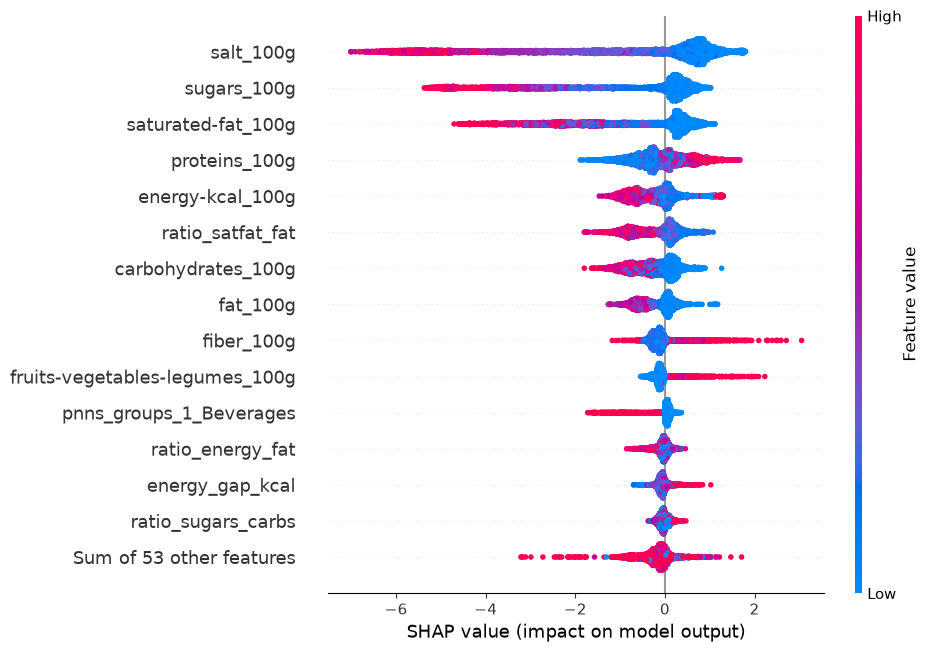

In [33]:
b_index = GRADES.index("b")
shap.plots.beeswarm(shap_values[:, :, b_index], max_display=15)

**Lecture.** Le grade b est poussé par le peu de sel, de sucres et de saturés, et par
beaucoup de fibres et de fruits et légumes. Le rayon « Beverages » l'en éloigne. Le sel
a l'effet le plus large : une fiche salée sort presque toujours de b.

### Une confusion expliquée produit par produit

Pour l'erreur la plus confiante de chaque sens (b prédit a, b prédit c), deux cascades :
la contribution de chaque feature au grade **prédit**, puis au grade **réel** b. Les
features qui séparent les deux cascades sont celles qui ont fait basculer le modèle.

b prédit a — Pate Des Cevennes (3048301401246), score officiel 1


,pnns_groups_1,pnns_groups_2,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,salt_100g,fiber_100g,fruits-vegetables-legumes_100g,nova_group,additives_n
6108,Fish Meat Eggs,Processed meat,165.0,4.4,1.4,3.8,0.0,26.0,0.066,0.0,0.0,3,0


Contributions au grade a


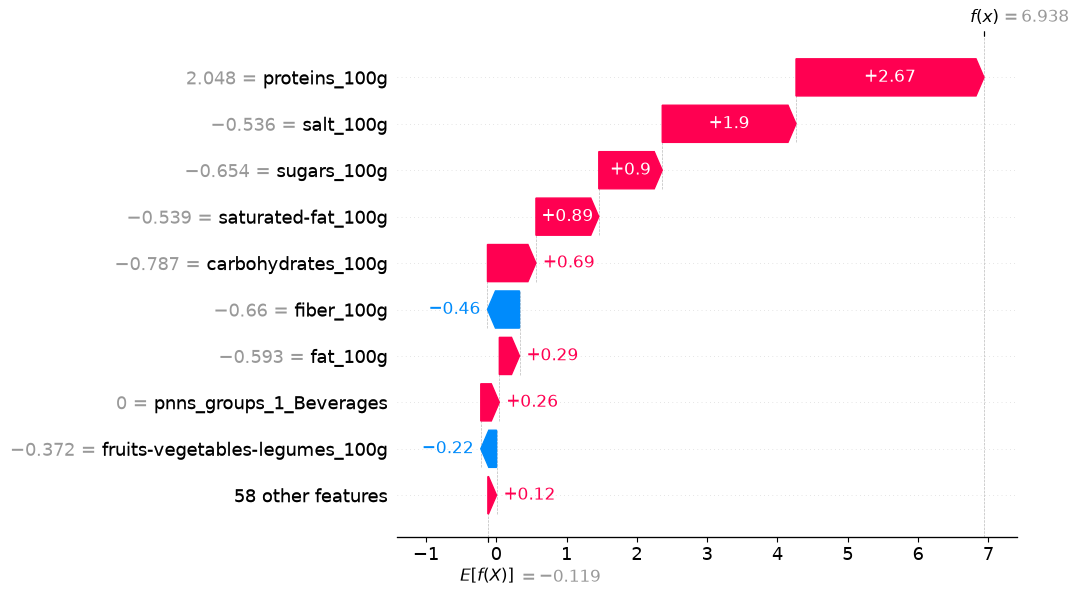

Contributions au grade b


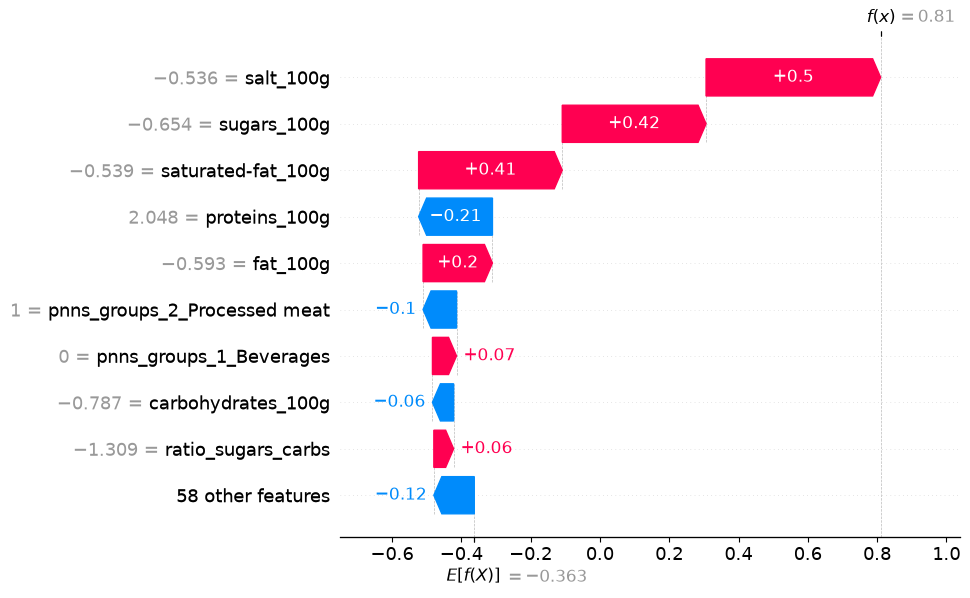

b prédit c — Piperade jambon Bayonne (3272931005165), score officiel 2


,pnns_groups_1,pnns_groups_2,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,salt_100g,fiber_100g,fruits-vegetables-legumes_100g,nova_group,additives_n
11377,Fruits and vegetables,Vegetables,57.0,2.0,0.5,6.1,5.3,3.1,1.5,NaN,NaN,<NA>,<NA>


Contributions au grade c


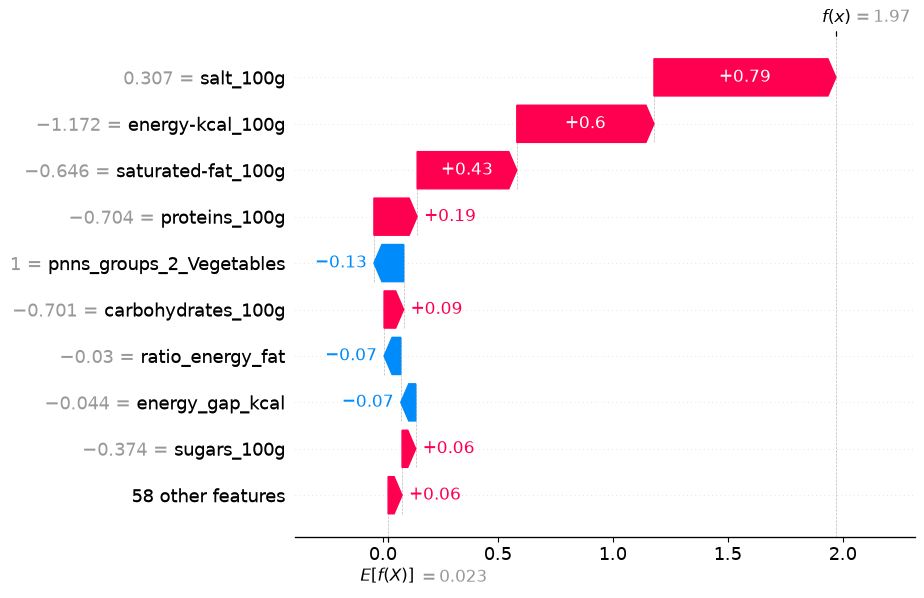

Contributions au grade b


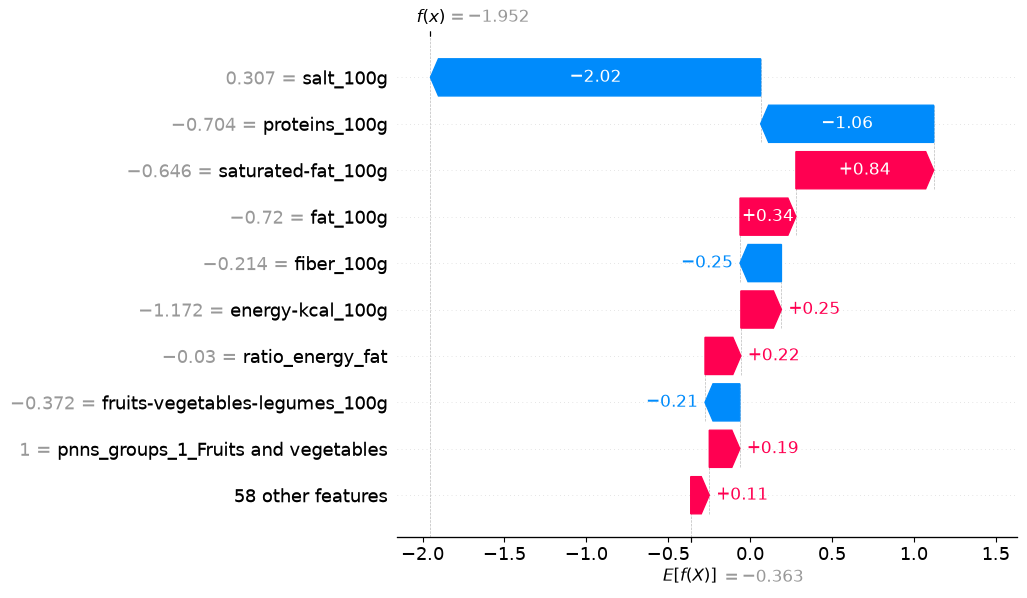

In [34]:
for name in ["b prédit a", "b prédit c"]:
    part = around_b[name]
    if part.empty:
        continue
    product = part.sort_values("confidence", ascending=False).index[0]
    row = X_test.index.get_loc(product)
    predicted = GRADES.index(analysis.loc[product, "pred"])
    print(f"{name} — {analysis.loc[product, 'product_name']} ({analysis.loc[product, 'code']}), "
          f"score officiel {analysis.loc[product, 'nutriscore_score']}")
    display(X_test.loc[[product]])
    for grade in (predicted, b_index):
        print(f"Contributions au grade {GRADES[grade]}")
        shap.plots.waterfall(shap_values[row, :, grade], max_display=10)

**Lecture.**

- **Pâté des Cévennes.** Les protéines (26 g) poussent vers a pour +2,67, alors qu'elles
  ne comptent presque pas pour b (−0,21). Le barème plafonne ces points pour la viande
  rouge, et aucune feature ne le dit au modèle. Le sel très bas (0,066 g, +1,9 vers a)
  est en plus invraisemblable pour un pâté : la fiche est probablement fausse.
- **Piperade.** Le sel (1,5 g) écarte b (−2,02), comme les protéines faibles (−1,06). La
  teneur en légumes manque et est imputée par la médiane : le modèle ne peut pas accorder
  les points « légumes » que le score officiel a comptés.